In [1]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [2]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

Estimated volume of the distribution: 0.488


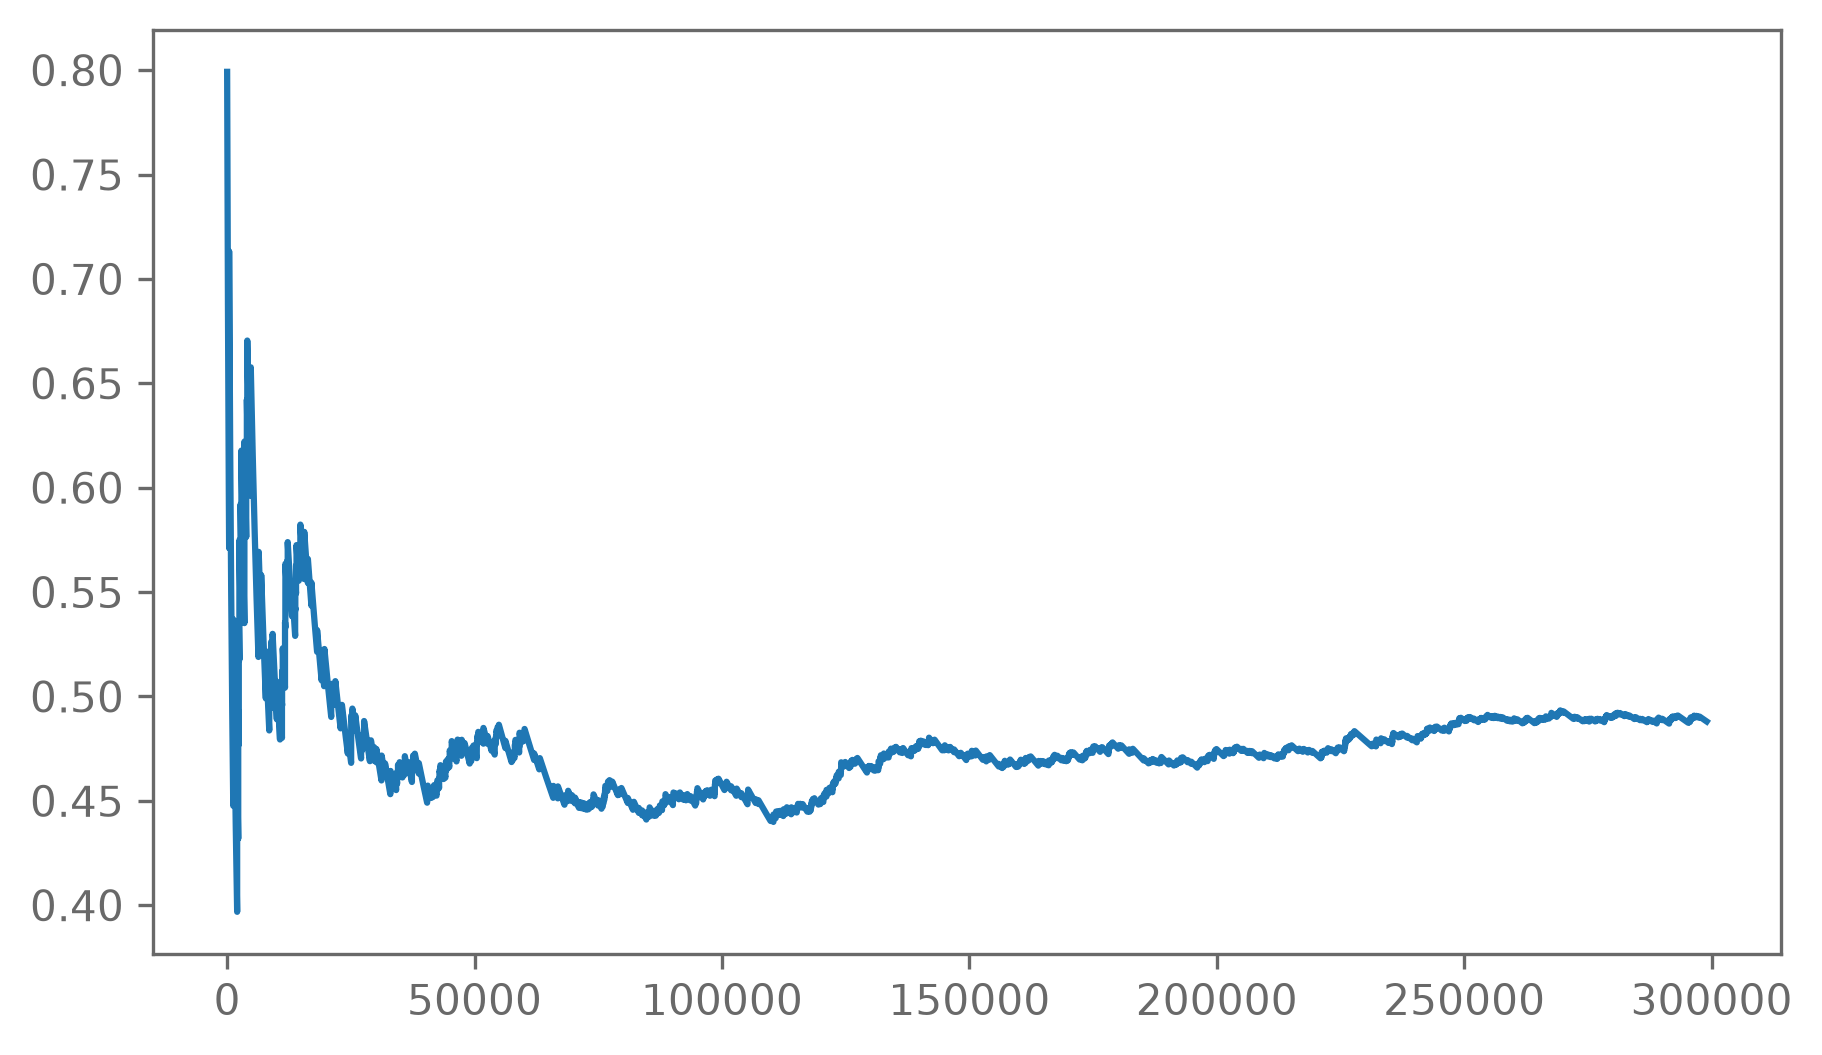

In [58]:
gaussian_at_origin = scipy.stats.multivariate_normal(mean=[5, 0], cov=[[2, 0], [0, 1]]
)

max_height = 2
n = 300000

#uniform sampler at origin from -5, -5 to 5, 5
sampling_distribution_uniform = scipy.stats.uniform(loc=[-5, -5], scale=[10, 10])
height_uniform_distribution = scipy.stats.uniform(loc=0, scale=max_height)

#sample n points from uniform distribution
samples_uniform = sampling_distribution_uniform.rvs(size=(n, 2))



accepted_samples = []
num_accepted_each_step = []
volume_estimate_each_step = []
num_accepted_samples_so_far = 0
for i in range(n):
    sampled_height = height_uniform_distribution.rvs()
    gaussian_height = gaussian_at_origin.pdf(samples_uniform[i])
    if sampled_height < gaussian_height:
        num_accepted_samples_so_far += 1
        accepted_samples.append(samples_uniform[i])
    num_accepted_each_step.append(num_accepted_samples_so_far)
        

    volume_estimate = 10 * 10 * max_height * num_accepted_samples_so_far / (i+1)
    volume_estimate_each_step.append(volume_estimate)
        
plt.plot(volume_estimate_each_step[1000:], label="Volume estimate")
print("Estimated volume of the distribution:", volume_estimate_each_step[-1])


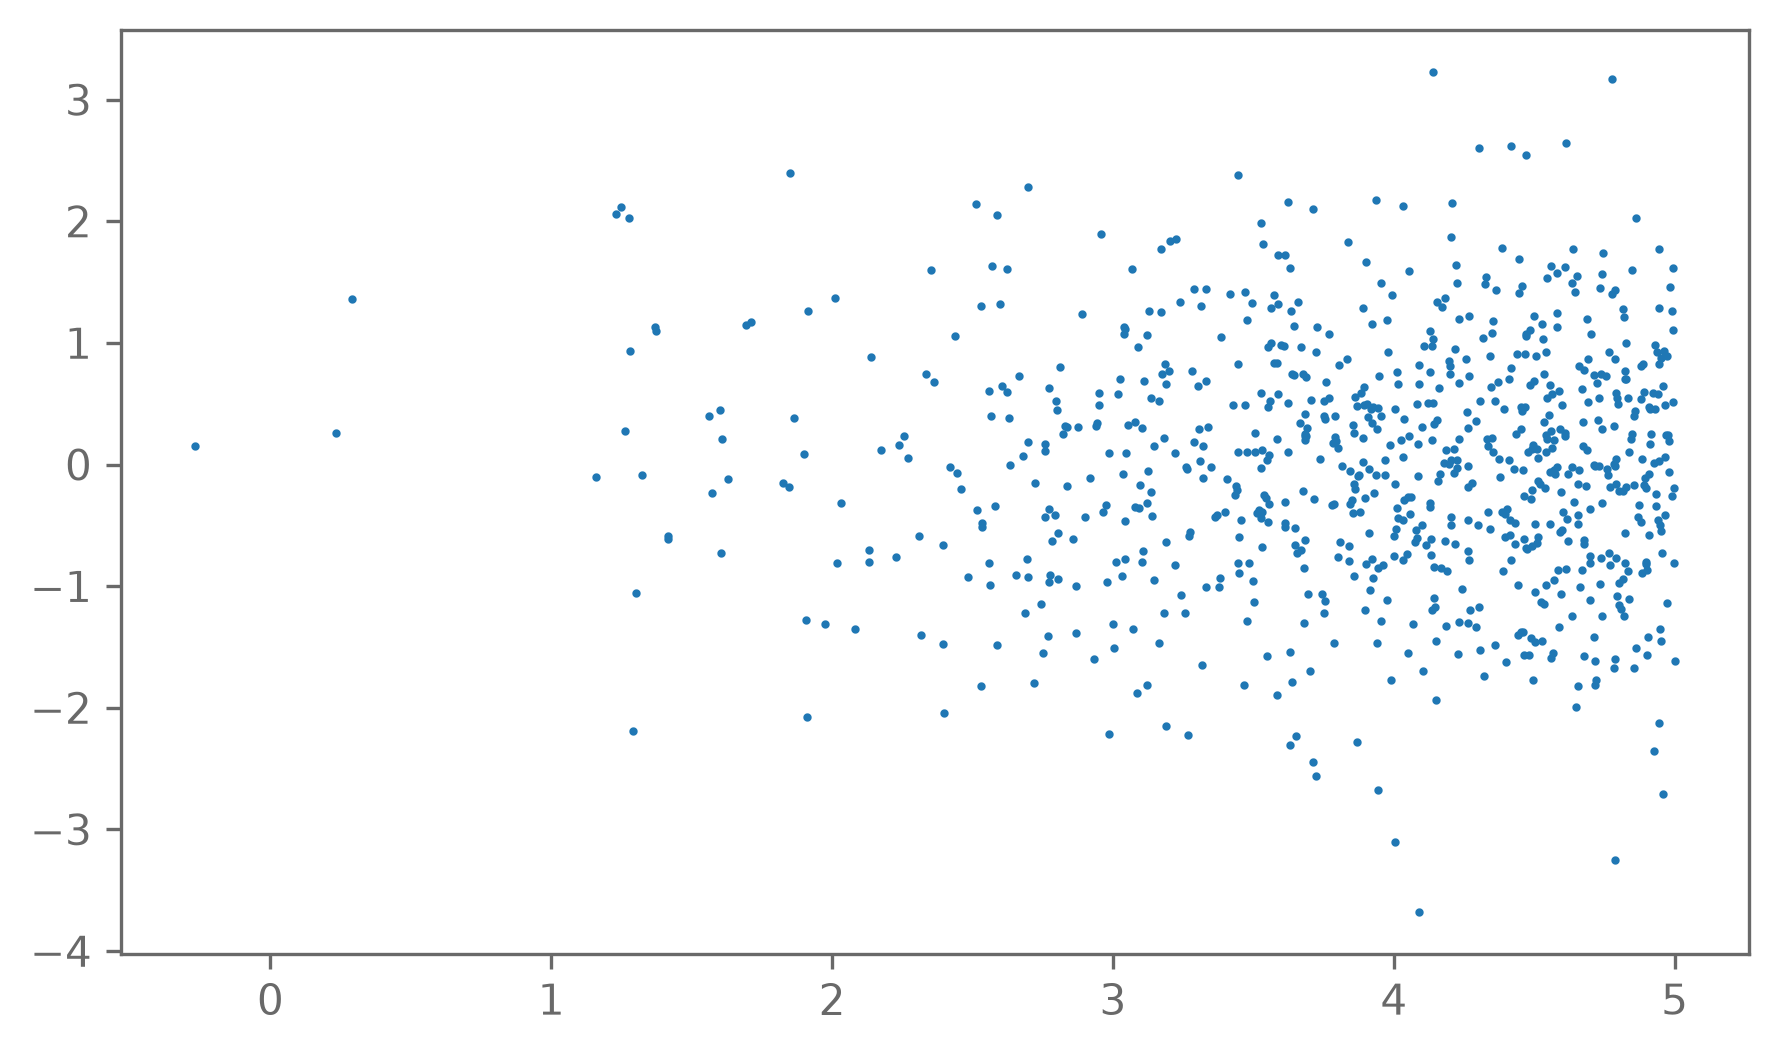

In [57]:
#plot accepted samples in 2d scatter plot

plt.scatter(*np.array(accepted_samples).T, s=1, label="Accepted samples")

1